In [29]:
import os, sys

# Make the ecCodes DLL findable (must run BEFORE importing xarray/cfgrib)
os.environ["PATH"] = os.path.join(sys.prefix, "Library", "bin") + os.pathsep + os.environ["PATH"]

import xarray as xr
import cfgrib
import snotelpy as sp
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [13]:
fname = '986f437998cb2c67bd913875435801ff.grib'

# The file mixes 6-hourly fields (u10, v10, tp) and 24-hourly snowfall (sf),
# so open_datasets returns a list with one Dataset per compatible group
dss = cfgrib.open_datasets(fname, backend_kwargs={'indexpath': '986f437998cb2c67bd913875435801ff.grib.5b7b6.idx'})


for i, d in enumerate(dss):
    print(f'===== Dataset {i}: {list(d.data_vars)} =====')
    print(d)
    print()

===== Dataset 0: ['u10', 'v10'] =====
<xarray.Dataset> Size: 1MB
Dimensions:            (number: 50, step: 185, latitude: 4, longitude: 5)
Coordinates:
  * number             (number) int64 400B 1 2 3 4 5 6 7 ... 45 46 47 48 49 50
  * step               (step) timedelta64[ns] 1kB 0 days 00:00:00 ... 46 days...
    valid_time         (step) datetime64[ns] 1kB 2021-12-16 ... 2022-01-31
  * latitude           (latitude) float64 32B 40.5 39.0 37.5 36.0
  * longitude          (longitude) float64 40B 252.0 253.5 255.0 256.5 258.0
    time               datetime64[ns] 8B 2021-12-16
    heightAboveGround  float64 8B 10.0
Data variables:
    u10                (number, step, latitude, longitude) float32 740kB ...
    v10                (number, step, latitude, longitude) float32 740kB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:     

c:\Users\tatev\miniforge3\envs\atoc\Lib\site-packages\cfgrib\xarray_store.py:51: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  o = xr.merge([o, ds], **kwargs)


In [89]:
import numpy as np

single_run = dss[1]['sf'].isel(number=0, step=40)

# Use .values or .item() to extract the raw step value
print(single_run['step'].values)

# Divide by np.timedelta64 instead of single_run.timedelta64
days = single_run.step / np.timedelta64(1, 'D')
print(days.item())  # Prints 40.0


3456000000000000 nanoseconds
40.0


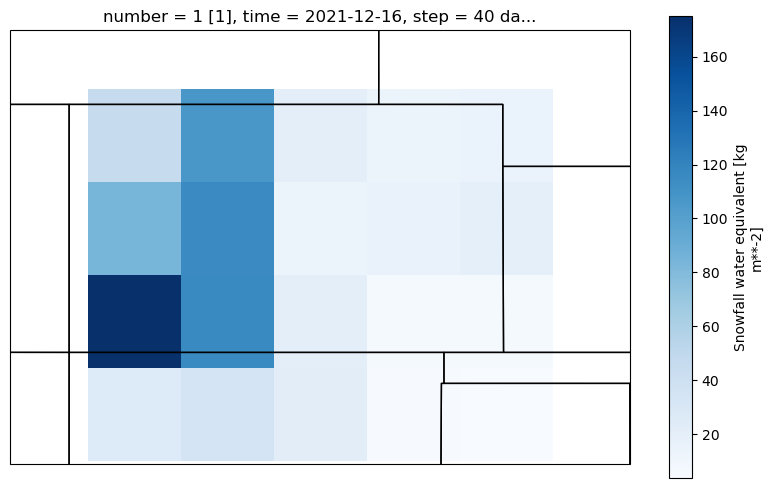

In [72]:
fig = plt.figure(figsize=(10,6))
ax = plt.axes(projection = ccrs.PlateCarree())


single_run.plot(
    ax = ax,
    transform=ccrs.PlateCarree(),
    cmap = 'Blues'
)



ax.add_feature(cfeature.STATES, linewidth=1.0, edgecolor="black")
ax.add_feature(cfeature.COASTLINE)


ax.set_extent([-110, -100, 35.2, 42.2], crs=ccrs.PlateCarree())

plt.show()


DTypePromotionError: The DType <class 'numpy.dtypes.TimeDelta64DType'> could not be promoted by <class 'numpy.dtypes.Float64DType'>. This means that no common DType exists for the given inputs. For example they cannot be stored in a single array unless the dtype is `object`. The full list of DTypes is: (<class 'numpy.dtypes.TimeDelta64DType'>, <class 'numpy.dtypes.Float64DType'>)

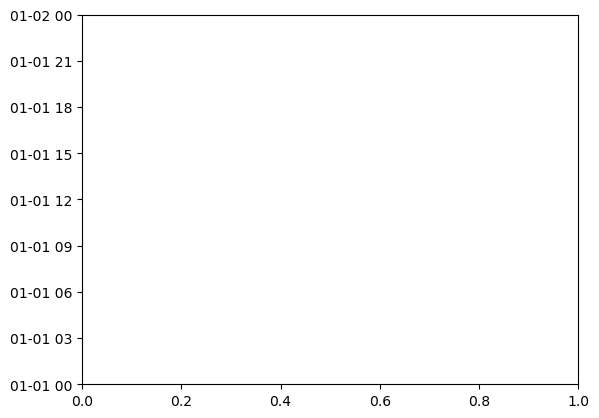

In [73]:
plt.scatter(x = single_run['step'], y = single_run['valid_time'])

In [84]:
ds = sp.get_stations([":CO:SNTL"],elements=['WTEQ'],hucs=140100) #colorado basin




ds = sp.get_stations([":CO:SNTL"],elements=['WTEQ'],hucs=110200) # san jauns 





## RMSE

In [ ]:
sp.fetch_snotel(hucs = 140100,elements=['WTEQ'],duration="Daily",start_date='')